In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from sklearn.preprocessing import scale

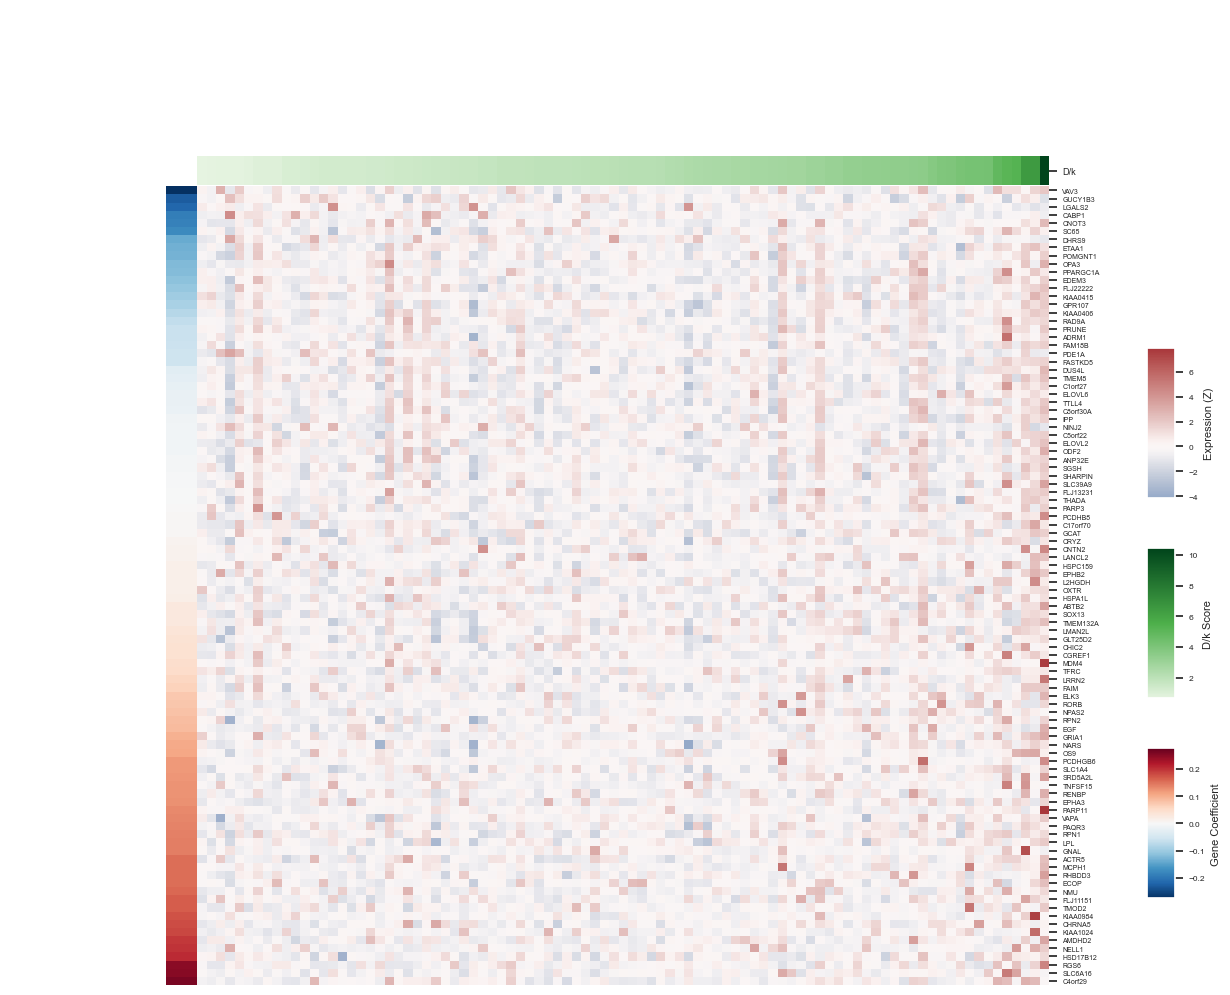

In [1]:
# --- 1. Data Loading and Preprocessing ---
predictive_genes = pd.read_csv("FullGenes.csv")
exp = pd.read_csv("../GBM.transcriptome__ht_hg_u133a__broad_mit_edu__Level_3__gene_rma__data.data.txt", sep="\t", low_memory=False)
exp = exp.iloc[1:]
tcga = pd.read_csv("../Dks_7_30_25.csv")

exp = exp.reset_index(drop=True).set_index("Hybridization REF")
exp.columns = exp.columns.str[0:12]
dat = tcga[tcga['D/k'].notna()].copy()
dat['D/k'] = pd.to_numeric(dat['D/k'])
d_k = dat[['id', 'D/k']]
d_k.columns = ["Patient.ID", "D/k"]
d_k = d_k.set_index("Patient.ID")

inc_samples = np.intersect1d(exp.columns, list(d_k.index))
d_k = d_k.loc[inc_samples]
exp = exp.loc[:, inc_samples]
exp2 = exp.apply(pd.to_numeric)

scaled_array = scale(exp2, axis=1)
scaled_exp = pd.DataFrame(scaled_array, index=exp2.index, columns=exp2.columns)
scaled_exp = scaled_exp.loc[predictive_genes['gene']]

# --- Top Annotation (D/k Score) ---
cmap_dk = mcolors.LinearSegmentedColormap.from_list(
    "dk_cmap", ["#e6f4e1", "#4daf4a", "#00441b"] 
)
norm = mcolors.Normalize(vmin=d_k["D/k"].min(), vmax=d_k["D/k"].max())
mapper = cm.ScalarMappable(norm=norm, cmap=cmap_dk)

d_k_sorted = d_k.sort_values(by="D/k")
sample_order = d_k_sorted.index
col_colors_df = pd.DataFrame({
    "D/k": d_k_sorted["D/k"].map(mapper.to_rgba)
}, index=sample_order)

gexp_sorted = scaled_exp[sample_order]

# --- Left Annotation (Gene Coefficient) ---
row_metric = predictive_genes.set_index('gene')['coef']
row_metric = row_metric.reindex(gexp_sorted.index)

# Red/Blue diverging colormap symmetrically centered on 0
max_abs = row_metric.abs().max()
cmap_row = plt.get_cmap("RdBu_r") 
norm_row = mcolors.Normalize(vmin=-max_abs, vmax=max_abs)
mapper_row = cm.ScalarMappable(norm=norm_row, cmap=cmap_row)

row_colors_series = row_metric.map(mapper_row.to_rgba)

# This removes the "coef" label at the bottom of the annotation bar
row_colors_series.name = ""

# --- 2. Plotting ---
figsize = (14, 10)
legend_x = 0.82      
legend_width = 0.02  
legend_font = 8
sns.set_theme(font_scale=0.6)

g = sns.clustermap(
    gexp_sorted,
    figsize=figsize,     
    col_cluster=False,
    row_cluster=False,
    yticklabels=True,
    xticklabels=False,
    col_colors=col_colors_df,
    row_colors=row_colors_series,
    cmap="vlag",
    center=0.0,
    cbar_pos=None,        # Hide default legend
    dendrogram_ratio=(0.15, 0.15)
)

g.fig.subplots_adjust(right=0.75)
g.ax_heatmap.set_ylabel("")
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_ymajorticklabels(), fontsize=5)

# A. Expression Legend
cax_main = g.fig.add_axes([legend_x, 0.5, legend_width, 0.15])
plt.colorbar(g.ax_heatmap.collections[0], cax=cax_main)
cax_main.set_ylabel("Expression (Z)", fontsize=legend_font)
cax_main.tick_params(labelsize=6)

# B. D/k Legend
cax_dk = g.fig.add_axes([legend_x, 0.3, legend_width, 0.15])
plt.colorbar(mapper, cax=cax_dk)
cax_dk.set_ylabel("D/k Score", fontsize=legend_font)
cax_dk.tick_params(labelsize=6)

# C. Row Metric Legend
cax_row = g.fig.add_axes([legend_x, 0.1, legend_width, 0.15])
plt.colorbar(mapper_row, cax=cax_row)
cax_row.set_ylabel("Gene Coefficient", fontsize=legend_font)
cax_row.tick_params(labelsize=6)

plt.show()